In [43]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import jlinops

from matplotlib.backends.backend_pdf import PdfPages


from scipy.linalg import qr, qr_insert
from fastprogress import progress_bar
import scipy.sparse as sps
from scipy.sparse.linalg import svds

from trips.utilities.weights import smoothed_holder_weights
from trips.utilities.reg_param.discrepancy_principle import discrepancy_principle
from modified_gcv import generalized_crossvalidation

# Toy problem

In [61]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.1
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=10, mode="reflect")
noisy_signal = A.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

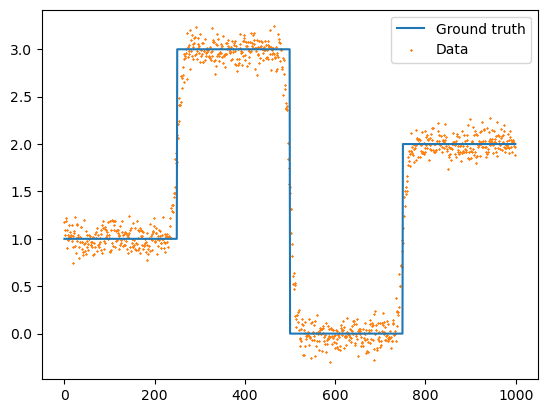

In [62]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization matrix

In [63]:
Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

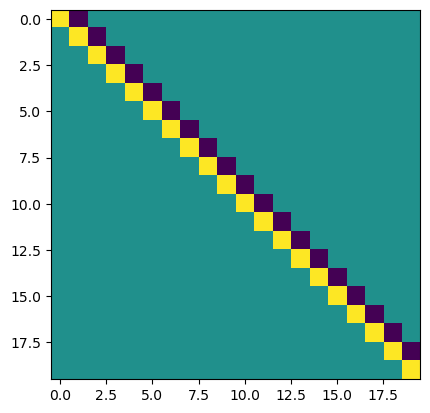

In [64]:
plt.imshow(Lmat.toarray()[:20,:20])
plt.show()

# MMGKS class

In [65]:
import scipy.optimize as op
from modified_gcv import gcv_numerator, gcv_denominator

In [89]:
class RMMGKS:
    """Implements a MMGKS solver for problems of the form
        argmin_x  || A x - b ||_2^2 + \lambda || L x ||_q^q.

    If noise_var is provided, then the problem solved is 
        argmin_x  (1/noise_var)*|| A x - b ||_2^2 + \lambda || L x ||_q^q.

    """

    def __init__(self, A, L, b, noise_var=None):

        # Bind
        self._A = A
        self.L = L
        self._b = b
        self.noise_var = noise_var
        self.n = A.shape[1]
        self.m = A.shape[0]
        self.k = L.shape[0]

        # Whiten?
        if self.noise_var is not None:
            self.noise_stdev = np.sqrt(self.noise_var)
            self.A = (1.0/noise_stdev)*self._A
            self.b = (1.0/noise_stdev)*self._b
        else:
            self.noise_stdev = None
            self.A = self._A
            self.b = self._b


    def build_initial_basis(self, dim):
        """Builds the initial basis.
        """

        Atb = self.A.T @ self.b

        V = np.zeros((self.n, dim))
        V[:,0] = Atb
        tmp = Atb.copy()
        for j in range(1,dim):
            tmp = self.A.T @ (self.A @ tmp)
            V[:,j] = tmp.copy()

        # V = np.random.normal(size=(self.n, 5))

        # Orthogonalize
        qr_fac = np.linalg.qr(V)
        V = qr_fac.Q

        return V


    def build_adjusted_initial_basis(self, lambdah, w, dim):
        """Builds the adjusted initial basis.
        """
        Atb = self.A.T @ self.b

        V = np.zeros((self.n, dim))
        V[:,0] = Atb
        tmp = Atb.copy()
        for j in range(1, dim):
            tmp = self.A.T @ (self.A @ tmp) + lambdah*( self.L.T @ ( w * w * (self.L @ tmp) ) )
            V[:,j] = tmp.copy()

        # Orthogonalize
        qr_fac = np.linalg.qr(V)
        V = qr_fac.Q

        return V
    

    def compress_basis(self, V, R_A, R_WL, x, Q_A, kmin, lambdah):
        """Compresses the basis using TSVD approach.
        """

        # Make H matrix
        H = np.vstack([R_A, np.sqrt(lambdah)*R_WL ])

        # Truncated SVD
        _, _, Wh = svds(H, k=kmin-1)
        W = Wh.T

        # Get new basis
        Vtilde = V @ W
        xnew = x -  Vtilde @ (Vtilde.T @ x)
        xnew /= np.linalg.norm(xnew)
        V = np.column_stack((Vtilde, xnew))

        # Orthogonalize
        qr_fac = np.linalg.qr(V)
        V = qr_fac.Q

        return V



    def solve(self, n_iter=100, init_dim=4, kmin=4, kmax=10, q=1.0, epsilon=1e-2, regparam="gcv", fixed_regparam=None, x0=None, x_true=None, gcv_gamma=0.1, plotting=False, pdf_name="demo.pdf", helping=False, **kwargs):
        """Driver for MMGKS solver.
        """
        assert kmin <= (init_dim + 2), "must have kmin >= init_dim+2 in this implementation"

        # Tracking
        tot_matvec_A = 0
        tot_matvec_L = 0 
        lambda_history = []
        residual_history = []
        rre_history = []
        cond_ests = []
        lambdah = 1.0

        # Initialization
        if x0 is None:
            x = self.A.T @ self.b
        else:
            x = x0
        
        if x_true is not None:
            x_true_norm = np.linalg.norm(x_true)
            rre_history.append( np.linalg.norm(x - x_true)/x_true_norm )

        # Plotting?
        if plotting:
            pdf = PdfPages(pdf_name)

        
        # Build initial basis and QR factor of AV
        V = self.build_initial_basis(init_dim)
        dim_size = init_dim
        AV = self.A @ V 
        tot_matvec_A += 2*init_dim
        tot_matvec_A += init_dim
        Q_A, R_A = qr(AV, mode='economic') 

        # Get initial LV
        LV = self.L @ V
        tot_matvec_L += init_dim

        for ii in progress_bar(range(2+n_iter)):

            # If we have just done two iterations, need to restart the basis
            if ii == 2:
                V = self.build_adjusted_initial_basis(lambdah, w, kmin)
                dim_size = kmin
                AV = self.A @ V 
                LV = self.L @ V
                tot_matvec_A += 2*dim_size
                tot_matvec_A += dim_size
                tot_matvec_L += 2*dim_size
                tot_matvec_L += dim_size
                Q_A, R_A = qr(AV, mode='economic')
                print("adjusted basis")

            
            # Update weights and get new QR factorization of W L V
            Lx = self.L @ x
            tot_matvec_L += 1
            w = smoothed_holder_weights( Lx, epsilon=epsilon, p=q)
            W = sps.diags(w)
            WLV = W @ LV
            Q_WL, R_WL = qr(WLV, mode='economic') 
            
            lambdah, fig = self.choose_lambdah_gcv(Q_A, R_A, R_WL, self.b, plotting=plotting, gcv_gamma=gcv_gamma, helping=helping)
            lambda_history.append(lambdah)

            if plotting:
                pdf.savefig(fig)
                plt.close(fig)

            
            # Obtain new solution
            y, _ , _, svals = np.linalg.lstsq(np.concatenate((R_A, np.sqrt(lambdah) * R_WL)), np.concatenate((Q_A.T @ self.b, np.zeros((R_WL.shape[0],)))), rcond=None)
            cond_est = np.amax(svals)/np.amin(svals)
            cond_ests.append(cond_est)
            x = V @ y

            if x_true is not None: rre_history.append( np.linalg.norm(x - x_true)/x_true_norm )

            # if ii >= R_WL.shape[0]:
            #     break
            
            # Get new residual
            v = AV @ y
            v = v - self.b
            u = LV @ y
            ra = AV @ y - self.b
            ra = self.A.T @ ra
            rb = W @ (LV @ y)
            rb = self.L.T @ rb
            r = ra + lambdah * rb
            r = r - V @ (V.T @ r) # re-orthogonalize
            #r = r - V @ (V.T @ r)
            #normed_r = r / np.linalg.norm(r) 
            vn = r / np.linalg.norm(r)
            V = np.column_stack((V, vn))
            Avn = self.A @ vn
            AV = np.column_stack((AV, Avn))
            Lvn = vn
            Lvn = self.L * vn
            LV = np.column_stack((LV, Lvn))
            tot_matvec_A += 2
            tot_matvec_L += 2
            residual_history.append(np.linalg.norm(r))
            dim_size += 1

            # Update QR factor for A
            # Q_A, R_A = qr_insert( Q_A, R_A, u = Avn, k=-1, which="col" )
            Q_A, R_A = qr(AV, mode='economic')
            

            # If dim_size == kmax, need to compress the basis
            if dim_size == kmax:

                # Update weights and get new QR factorization of W L V
                LV = self.L @ V
                tot_matvec_L += dim_size
                WLV = W @ LV
                Q_WL, R_WL = qr(WLV, mode='economic') 
                
                # New basis
                V = self.compress_basis(V, R_A, R_WL, x, Q_A, kmin, lambdah)
                
                # Solve the problem over the new basis
                dim_size = kmin
                AV = self.A @ V 
                LV = self.L @ V
                tot_matvec_A += dim_size
                tot_matvec_L += dim_size
                Q_A, R_A = qr(AV, mode='economic')

                x = V @ (V.T @ x)


                # # # Obtain new solution
                # y, _ , _, svals = np.linalg.lstsq(np.concatenate((R_A, np.sqrt(lambdah) * R_WL)), np.concatenate((Q_A.T @ self.b, np.zeros((R_WL.shape[0],)))), rcond=None)
                # cond_est = np.amax(svals)/np.amin(svals)
                # cond_ests.append(cond_est)
                # x = V @ y         
                
             
                print("compressed basis")

            
        # Package output
        data = {
            "x": x,
            "w": w,
            "tot_matvec_A": tot_matvec_A,
            "tot_matvec_L": tot_matvec_L,
            "residual_history": np.asarray(residual_history),
            "lambda_history": np.asarray(lambda_history),
            "V": V,
            "cond_ests": np.asarray(cond_ests),
        }

        if x_true is not None:
            data["rre_history"] = np.asarray(rre_history)

        if plotting:
            pdf.close()

        return data
    



    def choose_lambdah_gcv(self, Q_A, R_A, R_WL, b, gcv_gamma=0.1, plotting=False, helping=False):
        """Chooses a new lambdah parameter using cross validation. If plotting=True is passed,
        also makes a plot of the GCV functional.
        """

        # Build objective function (in terms of log lambda)
        #gcv_func = lambda log_reg_param: np.log( gcv_numerator(np.power(10, log_reg_param), Q_A, R_A, R_WL, b) ) - np.log( gcv_denominator(np.power(10,log_reg_param), R_A, R_WL, b ) ) 
        #gcv_func = lambda log_reg_param: gcv_numerator(np.exp(log_reg_param), Q_A, R_A, R_WL, b) / gcv_denominator(np.exp(log_reg_param), R_A, R_WL, b)

        def gcv_func(log_reg_param):
            inverted, _ , _, svals = np.linalg.lstsq(np.concatenate((R_A, np.sqrt( np.power(10, log_reg_param) ) * R_WL)), np.vstack( (  np.eye( R_A.T.shape[1] )  , np.zeros((R_WL.shape[0],R_A.T.shape[1]) ) ) ),rcond=None)
            Z = R_A @ inverted
            fac = gcv_gamma + (1.0 - gcv_gamma)*(1.0/R_A.shape[0])*np.trace( Z @ Z )
            return np.log(fac) + np.log( gcv_numerator(np.power(10, log_reg_param), Q_A, R_A, R_WL, b) ) - np.log( np.abs( gcv_denominator(np.power(10,log_reg_param), R_A, R_WL, b ) ) ) 

        # Compute a solution
        log_lambdah_star = op.fminbound(func = gcv_func, x1 = -12, x2 = 12, args=(), xtol=1e-12, maxfun=1000, full_output=0, disp=0) ## should there be tol here?
        log_lambdah_star_eval = gcv_func(log_lambdah_star)
        lambdah_star = np.power(10,log_lambdah_star)
        
        # If plotting?
        fig = None
        if plotting:

            log_lambdahs = np.linspace(-12, 12, 100)
            evals = []
            for log_lambdah in log_lambdahs:
                evals.append( gcv_func(log_lambdah) )

            fig, axs = plt.subplots()

            axs.plot(log_lambdahs, evals, linestyle='--', color='b') 
            axs.scatter(log_lambdahs, evals, marker='x', color='b', label="Sample points") 
            axs.set_xlabel("$\\log_{10} \\lambda$")
            axs.set_ylabel("$\\ln \\text{GCV}(\\lambda)$")
            axs.set_title(f"Modified GCV curve, gamma = {gcv_gamma}")

            # Overwrite if a grid point is better?
            if helping:
                
                min_idx = np.argmin(evals)
                min_eval = np.amin(evals)
                grid_opt_log_lambdah = log_lambdahs[min_idx]
                if log_lambdah_star_eval > min_eval:
                    axs.set_title(f"Modified GCV curve, gamma = {gcv_gamma}, overwrote!")
                    log_lambdah_star = grid_opt_log_lambdah
                    lambdah_star = np.power(10, log_lambdah_star)
                    log_lambdah_star_eval = min_eval

            axs.scatter(log_lambdah_star, log_lambdah_star_eval, marker="o", color="red", label="Optimized $\\lambda$")
            axs.legend()

        lambdah_star = 1.0

        return lambdah_star, fig
    
    
    

# Test it out

In [90]:
rmmgks_solver = RMMGKS(A, L, noisy_signal, noise_var=noise_var)

In [91]:
data = rmmgks_solver.solve(n_iter=200, init_dim=20, kmin=20, kmax=35, epsilon=1e-2, q=1.0, x_true=ground_truth, fixed_reparam=1.0, helping=True, gcv_gamma=0.1, plotting=True, pdf_name="demo3.pdf")
print(f"total matvecs with A/A^T: {data['tot_matvec_A']}")
print(f"total matvecs with L/L^T: {data['tot_matvec_L']}")

adjusted basis
compressed basis
compressed basis
compressed basis
compressed basis
compressed basis
compressed basis
compressed basis
compressed basis
compressed basis
compressed basis
compressed basis
compressed basis
compressed basis
total matvecs with A/A^T: 784
total matvecs with L/L^T: 1401


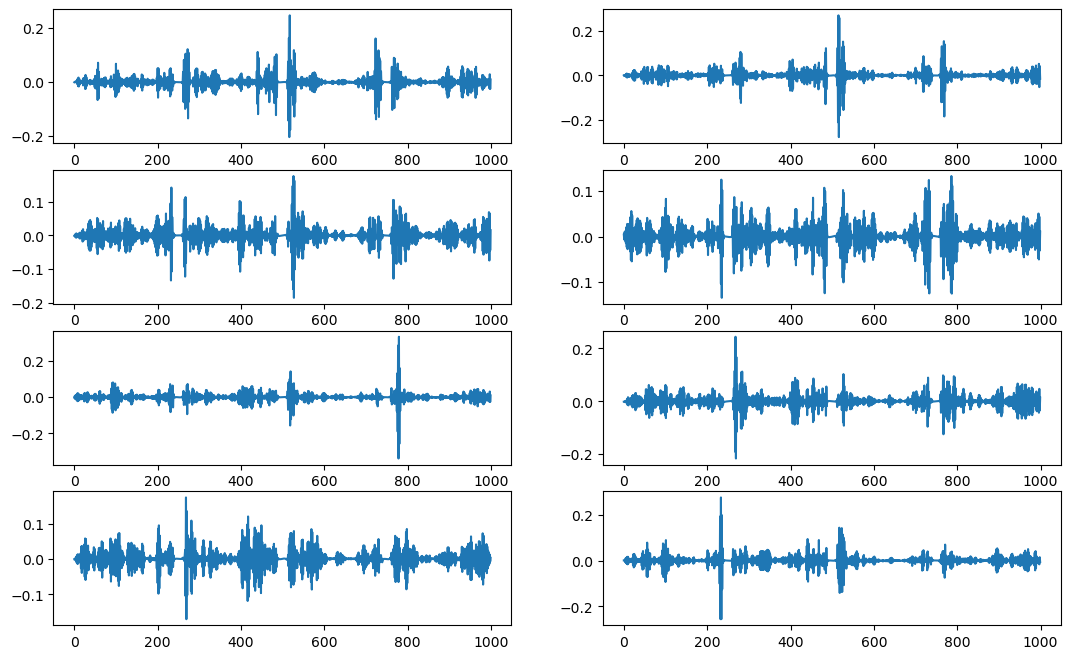

In [100]:
fig, axs = plt.subplots(4,2,figsize=(13,8))

for j, ax in enumerate(axs.reshape(-1)):
    ax.plot(data["V"][:,j])

In [101]:
data["V"].shape

(1000, 25)

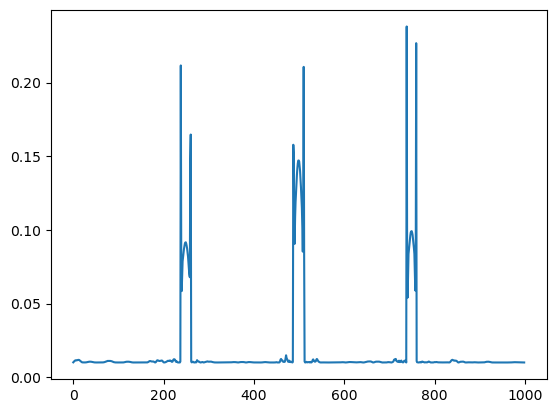

In [102]:
plt.plot(1.0/data["w"])
plt.show()

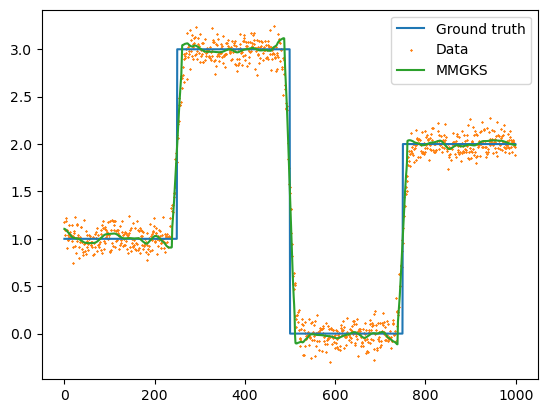

In [103]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.plot(grid, data["x"], label="MMGKS", color="C2")
plt.legend()
plt.show()
plt.show()

In [108]:
data["rre_history"][-1]

0.09617146427028286

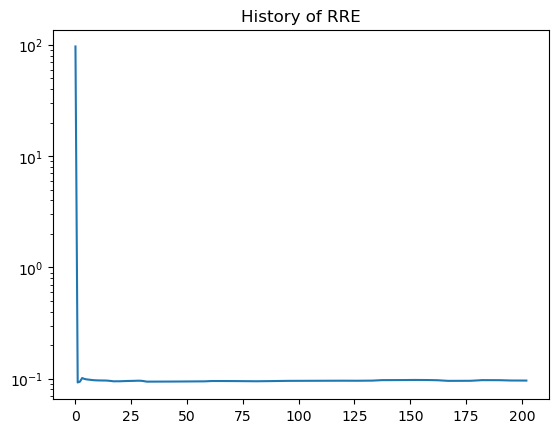

In [104]:
plt.plot(data["rre_history"])
plt.yscale("log")
plt.title("History of RRE")
plt.show()

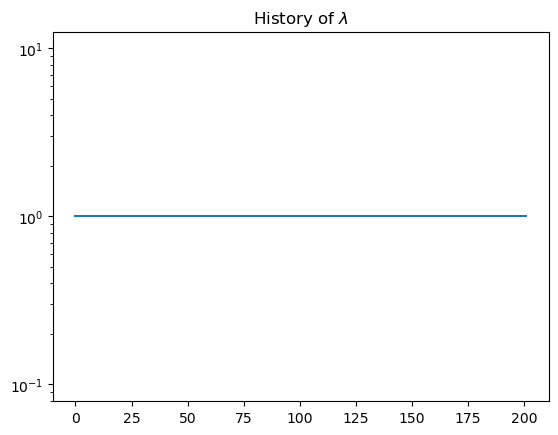

In [109]:
plt.plot(data["lambda_history"])
plt.title("History of $\\lambda$")
plt.yscale("log")
plt.show()

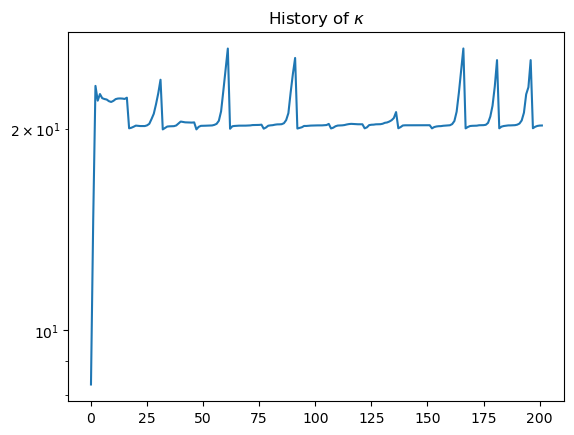

In [110]:
plt.plot(data["cond_ests"])
plt.yscale("log")
plt.title("History of $\\kappa$")
plt.show()

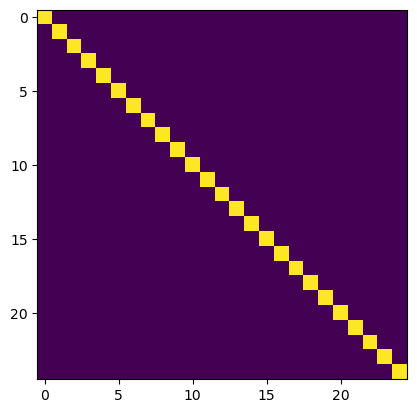

In [107]:
plt.imshow( data["V"].T @ data["V"] )
plt.show()